In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns

In [ ]:
df = pd.read_csv('AirQualityUCI.csv')

In [ ]:
#1
print(df.shape)
print(df.info())

(9471, 17)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9471 entries, 0 to 9470
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   object 
 1   Time           9357 non-null   object 
 2   CO(GT)         9357 non-null   float64
 3   PT08.S1(CO)    9357 non-null   float64
 4   NMHC(GT)       9357 non-null   float64
 5   C6H6(GT)       9357 non-null   float64
 6   PT08.S2(NMHC)  9357 non-null   float64
 7   NOx(GT)        9357 non-null   float64
 8   PT08.S3(NOx)   9357 non-null   float64
 9   NO2(GT)        9357 non-null   float64
 10  PT08.S4(NO2)   9357 non-null   float64
 11  PT08.S5(O3)    9357 non-null   float64
 12  T              9357 non-null   float64
 13  RH             9357 non-null   float64
 14  AH             9357 non-null   float64
 15  Unnamed: 15    0 non-null      float64
 16  Unnamed: 16    0 non-null      float64
dtypes: float64(15), object(2)
memory usage: 1

In [ ]:
#2
df = df.replace(-200, np.nan)
print(df.isnull().sum())

Date              114
Time              114
CO(GT)           1797
PT08.S1(CO)       480
NMHC(GT)         8557
C6H6(GT)          480
PT08.S2(NMHC)     480
NOx(GT)          1753
PT08.S3(NOx)      480
NO2(GT)          1756
PT08.S4(NO2)      480
PT08.S5(O3)       480
T                 480
RH                480
AH                480
Unnamed: 15      9471
Unnamed: 16      9471
dtype: int64


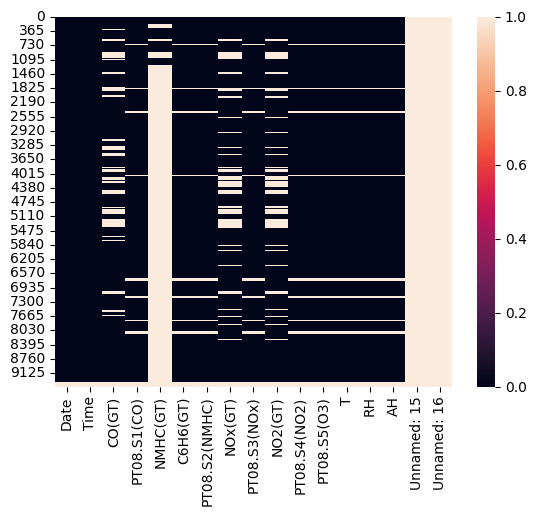

In [ ]:
#3
import seaborn as sns
import matplotlib.pyplot as plt


sns.heatmap(df.isnull())
plt.show()

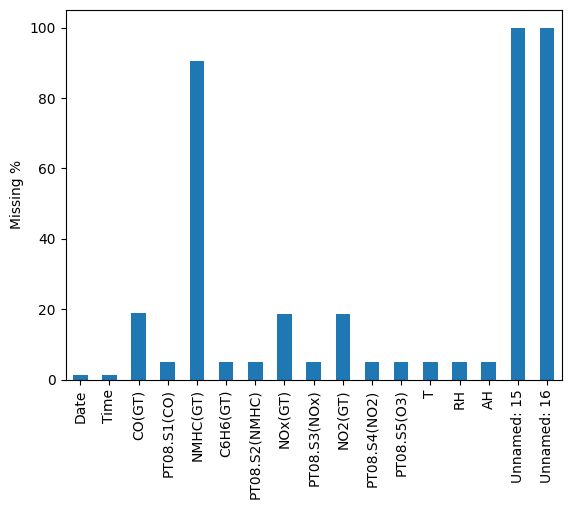

In [ ]:
(df.isnull().mean() * 100).plot(kind='bar')

plt.ylabel("Missing %")
plt.show()

In [ ]:
#4
missing = df.isnull().mean()
df = df.drop(columns=missing[missing > 0.40].index)
print(df.columns)

Index(['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'C6H6(GT)', 'PT08.S2(NMHC)',
       'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)',
       'T', 'RH', 'AH'],
      dtype='object')


In [ ]:
#5
num_cols = df.select_dtypes(include='number').columns

for col in num_cols:
    if df[col].isnull().mean() < 0.10:
        df[col] = df[col].fillna(df[col].mean())

In [ ]:
#6
num_cols = df.select_dtypes(include='number').columns

for col in num_cols:
    missing = df[col].isnull().mean()
    if 0.10 <= missing <= 0.40:
        df[col] = df[col].fillna(df[col].median())


In [ ]:
#7
print(df.isnull().sum())

Date             114
Time             114
CO(GT)             0
PT08.S1(CO)        0
C6H6(GT)           0
PT08.S2(NMHC)      0
NOx(GT)            0
PT08.S3(NOx)       0
NO2(GT)            0
PT08.S4(NO2)       0
PT08.S5(O3)        0
T                  0
RH                 0
AH                 0
dtype: int64


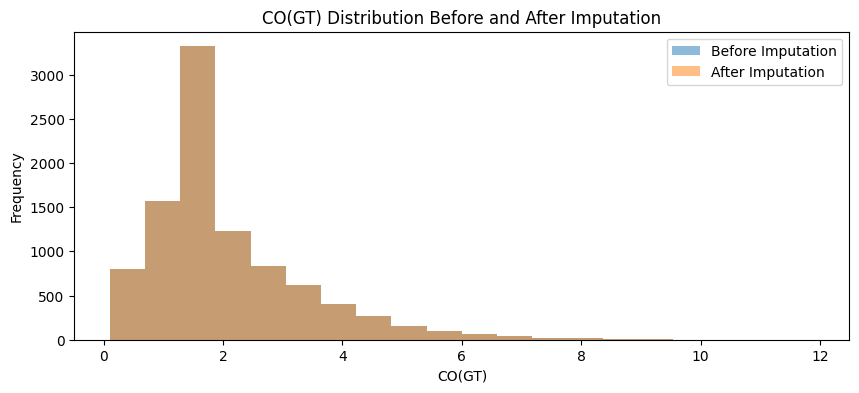

In [ ]:
#8
import seaborn as sns
co_before = df["CO(GT)"].copy()
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))

plt.hist(co_before.dropna(), bins=20, alpha=0.5, label="Before Imputation")
plt.hist(df["CO(GT)"], bins=20, alpha=0.5, label="After Imputation")

plt.xlabel("CO(GT)")
plt.ylabel("Frequency")
plt.title("CO(GT) Distribution Before and After Imputation")
plt.legend()
plt.show()